In [4]:
!pip install numpy scipy matplotlib statsmodels

## DS 7 – Veľkosť vzorky a sila testu

**Vstupné parametre:**
- `p1` = baseline konverzný pomer (napr. 0.10 = 10 %)
- `p2` = očakávaný konverzný pomer po zmene (napr. 0.12 = +20 % relatívne)
- `alpha` = hladina významnosti (0.05)
- `power` = sila testu / 1 - beta (0.80)

**Čo počítame:**
- n = koľko používateľov potrebujem v každej skupine
- power curve = ako sila testu rastie s n

In [5]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Parametre testu
p1 = 0.10        # baseline konverzný pomer
mde = 0.20       # minimálna detekovateľná zmena (relatívna, napr. +20 %)
p2 = p1 * (1 + mde)  # = 0.12
alpha = 0.05
power = 0.80

print(f"Baseline: {p1:.2%}  →  Cieľ: {p2:.2%}  (MDE: +{mde:.0%})")

Baseline: 10.00%  →  Cieľ: 12.00%  (MDE: +20%)


In [6]:
def sample_size(p1, p2, alpha=0.05, power=0.80):
    """Výpočet veľkosti vzorky pre dvojproporcný z-test."""
    z_alpha = stats.norm.ppf(1 - alpha / 2)  # dvojstranný test
    z_beta  = stats.norm.ppf(power)
    
    numerator   = (z_alpha + z_beta) ** 2 * (p1*(1-p1) + p2*(1-p2))
    denominator = (p2 - p1) ** 2
    
    return int(np.ceil(numerator / denominator))

n = sample_size(p1, p2, alpha, power)
print(f"Potrebná veľkosť vzorky: {n:,} na skupinu ({2*n:,} celkovo)")

Potrebná veľkosť vzorky: 3,839 na skupinu (7,678 celkovo)


In [7]:
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower

effect_size = proportion_effectsize(p1, p2)  # Cohen's h
n_statsmodels = NormalIndPower().solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    alternative='two-sided'
)
print(f"Overenie (statsmodels): {int(np.ceil(n_statsmodels)):,} na skupinu")

Overenie (statsmodels): 3,835 na skupinu


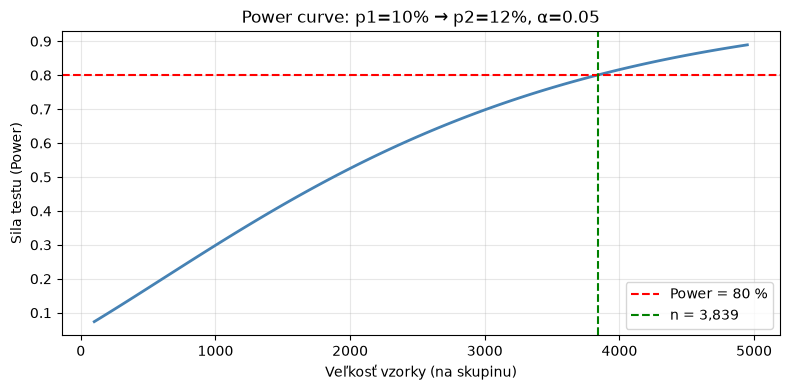

In [8]:
ns = np.arange(100, 5000, 50)
powers = [
    NormalIndPower().solve_power(
        effect_size=effect_size, nobs1=n, alpha=alpha, alternative='two-sided'
    )
    for n in ns
]

plt.figure(figsize=(8, 4))
plt.plot(ns, powers, color='steelblue', linewidth=2)
plt.axhline(y=0.80, color='red', linestyle='--', label='Power = 80 %')
plt.axvline(x=n, color='green', linestyle='--', label=f'n = {n:,}')
plt.xlabel('Veľkosť vzorky (na skupinu)')
plt.ylabel('Sila testu (Power)')
plt.title(f'Power curve: p1={p1:.0%} → p2={p2:.0%}, α={alpha}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/power_curve.png', dpi=120)
plt.show()

In [9]:
print("=== VÝSLEDKY pre DS 8 ===")
print(f"n_per_group = {n}")
print(f"p1 (baseline) = {p1}")
print(f"MDE = {mde:.0%} → p2 = {p2}")
print(f"Power curve uložená: power_curve.png")

=== VÝSLEDKY pre DS 8 ===
n_per_group = 3839
p1 (baseline) = 0.1
MDE = 20% → p2 = 0.12
Power curve uložená: power_curve.png
